# 강원 웰니스관광 수용태세 진단

**질문** 강원은 숲·온천·바다 같은 웰니스 자원이 많고 2026년 3월 정부 웰니스 관광 클러스터로도 선정됐다. 그런데 이 자원이 실제로 관광객의 체류와 소비로 이어지고 있을까? 어느 시·군에서 무엇이 막혀 있을까?

**왜 중요한가** 한국관광공사는 지역 분산, 연박(체류) 확대, 의료·웰니스 같은 고부가 시장을 핵심 과제로 두고 있다. 시·군마다 막힌 지점이 다르면 처방도 달라야 한다.

| 가설 | 내용 | 지표 |
|---|---|---|
| A 체류 | 외지인은 오지만 자고 가지 않는 지역이 있다 | 관광 지출 중 숙박 비중 |
| B 비수기 | 계절 편차가 큰 지역은 비수기 공백이 크다 | 월 지출 최고÷최저 |
| C 객단가 | 스쳐 가는 지역은 1명당 지출이 낮다 | 외지인 1명당 관광 지출 |
| D 미스매치 | 웰니스 자원은 많은데 돈이 안 들어오는 지역이 있다 | 지출 점유 ÷ 웰니스 자원 점유 |

**데이터** 한국관광 데이터랩(이동통신 방문자, 신용카드 관광지출, 2025.11~2026.10, 강원 18개 시·군), 공공데이터포털 한국관광공사 웰니스관광정보·국문 관광정보 API.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "3_분석노트북" else Path.cwd()
sys.path.insert(0, str(ROOT / "2_코드" / "분석모듈"))

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from gwdx import config, diagnose, features, load
from gwdx.plotting import ACCENT, MUTED, TYPE_COLORS, WARN, plt, save, setup, short

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
FIG = config.FIGURES
FIG.mkdir(parents=True, exist_ok=True)
print("글꼴:", setup())

글꼴: ['Noto Sans CJK KR']


## 1. 데이터 불러오기와 품질 점검

데이터랩에서 내려받은 zip을 그대로 넣으면 머리글을 보고 종류를 구분한다. 18개 시·군 모두 12개월이 빠짐없이 있는지 먼저 확인한다.

In [2]:
dl = load.load_datalab()
api = load.load_api()
load.quality_report(dl)

,데이터,행 수,시작,끝,시군 수,시군별 달 수(최소~최대),시도
0,visitors_domestic,648,202511,202610,18,12~12,강원특별자치도
1,visitors_foreign,216,202510,202609,18,12~12,(지역명만 제공)
2,spending_domestic,3584,202511,202610,18,12~12,강원특별자치도
3,spending_foreign,3131,202511,202610,18,12~12,강원특별자치도


- 외국인 방문자는 데이터랩 품질 개선으로 2025.10~2026.09까지만 제공된다. 외국인 지표는 내국인 기간과 **겹치는 11개월(2025.11~2026.09)**만 쓴다.
- 외국인 방문자 파일에는 시도 이름 없이 '고성군'처럼 시군 이름만 있다. 강원을 고른 뒤 내려받았으므로 강원 고성군으로 본다.

In [3]:
f = features.build_features(dl, api)
d = diagnose.diagnose(f)
summary = features.gangwon_summary(f)
print("외국인 지표 기간:", f.attrs["foreign_months"])
{k: round(v, 1) for k, v in summary.items()}

외국인 지표 기간: (202511, 202609, 11)


{'외지인 1명당 지출(원)': np.float64(19833.2), '숙박 비중(%)': np.float64(8.7), '외국인 1명당 지출(원)': np.float64(16547.8)}

In [4]:
mix = features.category_mix(dl).drop(columns="관광총소비").sum().sort_values(ascending=False)
(mix / mix.sum() * 100).head(8).round(1).rename("강원 내국인 관광 지출 비중(%)").to_frame()

,강원 내국인 관광 지출 비중(%)
category,
일반외식업,33.00
기타관광쇼핑,20.30
육상운송,15.80
골프장,5.60
제과음료업,5.00
대형쇼핑몰,4.70
콘도,3.80
호텔,2.60


강원 관광 지출의 3분의 1이 일반 음식점이고, 숙박은 호텔·콘도·펜션·기타숙박을 다 합쳐도 9% 정도다.

## 2. 가설 A · 체류: 자고 가는가

숙박 비중이 5% 미만이면 '체류 약함'으로 본다. 카드 가맹점 위치로 집계되므로 숙박 앱으로 미리 결제한 숙박비는 빠질 수 있다. 숙박 비중은 실제보다 낮게 나올 수 있다는 점을 감안한다.

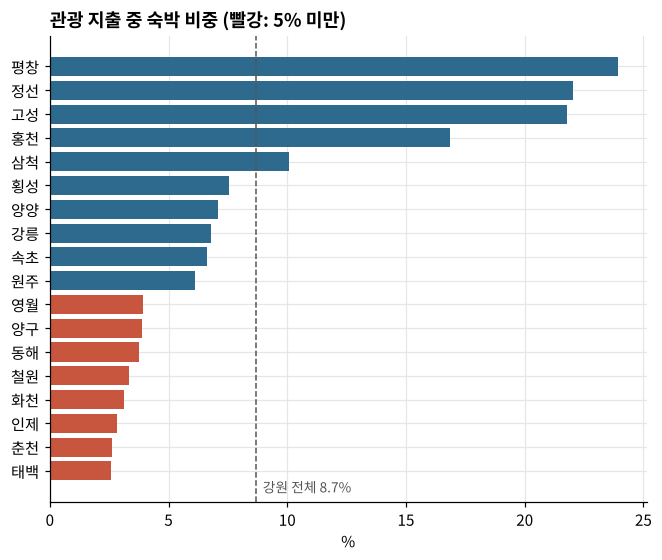

In [5]:
s = f.sort_values("lodging_share_pct")
fig, ax = plt.subplots(figsize=(7, 5.5))
colors = [WARN if v < config.DEFAULT_THRESHOLDS.lodging_share_pct else ACCENT for v in s["lodging_share_pct"]]
ax.barh([short(i) for i in s.index], s["lodging_share_pct"], color=colors)
ax.axvline(summary["숙박 비중(%)"], color="#555", ls="--", lw=1)
ax.text(summary["숙박 비중(%)"] + 0.3, -0.9, f"강원 전체 {summary['숙박 비중(%)']:.1f}%", fontsize=9, color="#555")
ax.set_title("관광 지출 중 숙박 비중 (빨강: 5% 미만)")
ax.set_xlabel("%")
save(fig, FIG / "A_lodging_share.png"); plt.show()

In [6]:
stay_vs_spend = stats.spearmanr(f["stay_listed"], f["spend_domestic_k"])
print(f"관광공사 등록 숙박 수 vs 관광 지출  Spearman ρ = {stay_vs_spend.statistic:.2f}, p = {stay_vs_spend.pvalue:.3f}")
f.loc[f["lodging_share_pct"] < 5, ["outsider_visitors", "lodging_share_pct", "spend_per_outsider"]].sort_values("outsider_visitors", ascending=False)

관광공사 등록 숙박 수 vs 관광 지출  Spearman ρ = 0.67, p = 0.003


,outsider_visitors,lodging_share_pct,spend_per_outsider
sigun,,,
춘천시,"29,818,832.00",2.64,"21,348.64"
동해시,"12,827,372.00",3.74,"18,096.99"
인제군,"12,253,502.00",2.81,"9,919.78"
영월군,"7,998,838.00",3.91,"14,160.32"
철원군,"6,574,175.00",3.33,"11,513.31"
태백시,"5,366,291.00",2.56,"17,976.61"
화천군,"4,225,746.00",3.10,"9,540.07"
양구군,"2,891,620.00",3.87,"11,534.43"


**결과** 리조트가 있는 평창·정선·고성·홍천만 숙박 비중이 15%를 넘는다. 춘천은 외지인이 강원 3위인데 숙박 비중이 2.6%로, 당일치기 성격이 뚜렷하다. 숙박 인프라(관광공사 등록 숙박 수)는 시·군 관광 지출과 강하게 함께 움직인다(ρ≈0.67).

## 3. 가설 B · 비수기: 계절을 얼마나 타는가

각 시·군의 월 지출을 그 시·군 월평균으로 나눴다. 1보다 크면 평소보다 많이 쓰는 달이다.

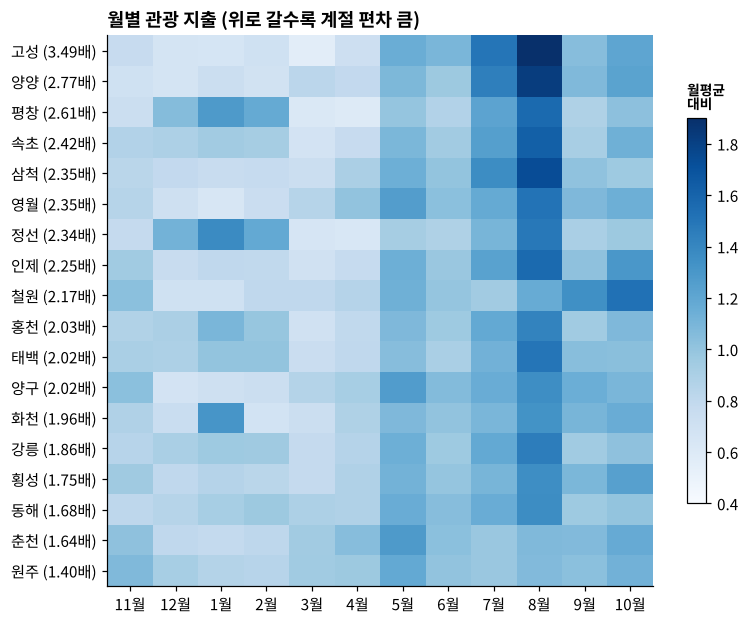

In [7]:
m = features.monthly_spending(dl).pivot(index="sigun", columns="ym", values="ratio_to_mean")
m = m.loc[f["seasonality_ratio"].sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(m.values, cmap="Blues", aspect="auto", vmin=0.4, vmax=1.9)
ax.set_xticks(range(m.shape[1]), [f"{int(str(c)[4:])}월" for c in m.columns])
ax.set_yticks(range(m.shape[0]), [f"{short(i)} ({f.loc[i, 'seasonality_ratio']:.2f}배)" for i in m.index])
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.7)
cb.ax.set_title("월평균\n대비", fontsize=9)
ax.set_title("월별 관광 지출 (위로 갈수록 계절 편차 큼)")
save(fig, FIG / "B_season_heatmap.png"); plt.show()

In [8]:
r = stats.spearmanr(f["outsider_share_pct"], f["seasonality_ratio"])
print(f"외지인 비율 vs 계절 편차  Spearman ρ = {r.statistic:.2f}, p = {r.pvalue:.4f}")

외지인 비율 vs 계절 편차  Spearman ρ = 0.74, p = 0.0004


**결과** 고성(3.49배)·양양(2.77배)·평창(2.61배)·속초(2.42배)가 계절을 가장 심하게 탄다. 대부분 8월에 몰리고, 평창·정선은 겨울(스키)에도 한 번 더 오른다. 관광객 의존도가 높은 지역일수록 계절 편차가 크다(ρ≈0.74). 계절을 덜 타는 웰니스(숲·온천·수면)가 비수기를 메울 수 있는 곳들이다.

## 4. 가설 C · 객단가: 1명당 얼마를 쓰는가

외지인 수 vs 1명당 지출  Spearman ρ = 0.72, p = 0.0007


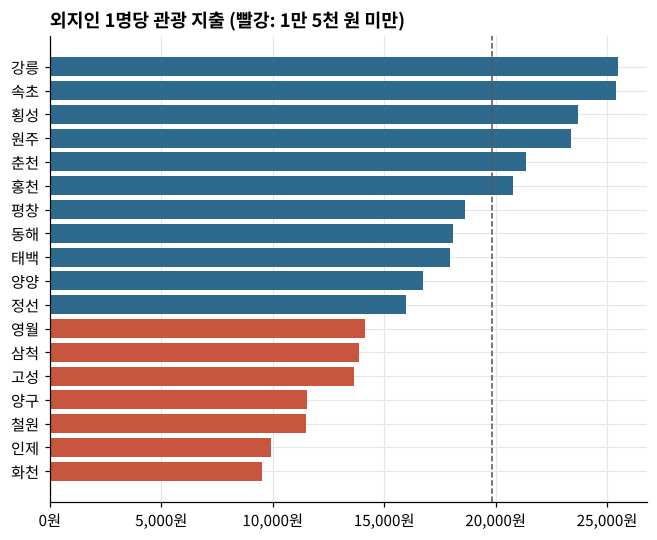

In [9]:
s = f.sort_values("spend_per_outsider")
fig, ax = plt.subplots(figsize=(7, 5.5))
colors = [WARN if v < config.DEFAULT_THRESHOLDS.spend_per_visitor else ACCENT for v in s["spend_per_outsider"]]
ax.barh([short(i) for i in s.index], s["spend_per_outsider"], color=colors)
ax.axvline(summary["외지인 1명당 지출(원)"], color="#555", ls="--", lw=1)
ax.set_title("외지인 1명당 관광 지출 (빨강: 1만 5천 원 미만)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}원")
save(fig, FIG / "C_spend_per_visitor.png"); plt.show()
r = stats.spearmanr(f["outsider_visitors"], f["spend_per_outsider"])
print(f"외지인 수 vs 1명당 지출  Spearman ρ = {r.statistic:.2f}, p = {r.pvalue:.4f}")

**결과** 강릉·속초(약 2만 5천 원)와 인제·화천(약 1만 원)은 2.5배 차이가 난다. 사람이 많이 오는 곳이 1명당도 많이 쓴다(ρ≈0.72). 인제는 외지인이 1,200만 명이 넘는데 1명당 지출은 최하위권이라 '지나가는 곳'일 가능성이 크다.

## 5. 가설 D · 미스매치: 자원만큼 돈이 들어오는가

웰니스 자원 = 관광공사 웰니스 관광지(15곳) + 휴양림·수목원(94곳). 강원 전체에서 각 시·군이 차지하는 자원 몫과 지출 몫을 비교한다. 대각선 아래는 자원에 비해 지출이 적은 곳이다.

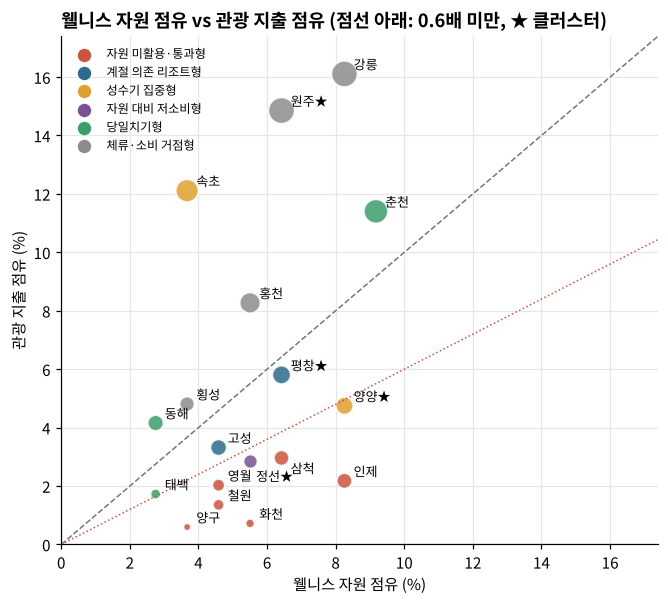

In [10]:
fig, ax = plt.subplots(figsize=(7, 6))
for t in config.TYPE_ORDER:
    g = d[d["type"] == t]
    ax.scatter(g["resource_share_pct"], g["spend_share_pct"], s=g["outsider_visitors"] / 1.2e5,
               color=TYPE_COLORS[t], alpha=0.85, edgecolor="white", lw=1.2)
    ax.scatter([], [], s=60, color=TYPE_COLORS[t], label=t)  # 범례용 같은 크기 표식
lim = max(f["resource_share_pct"].max(), f["spend_share_pct"].max()) * 1.08
ax.plot([0, lim], [0, lim], color="#777", ls="--", lw=1)
ax.plot([0, lim], [0, lim * config.DEFAULT_THRESHOLDS.resource_ratio], color=WARN, ls=":", lw=1)
for i, r in f.iterrows():
    offset = {"정선군": (4, -13), "삼척시": (6, -10)}.get(i, (6, 3))
    ax.annotate(short(i) + ("★" if r["wellness_cluster"] else ""), (r["resource_share_pct"], r["spend_share_pct"]),
                xytext=offset, textcoords="offset points", fontsize=8.5)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("웰니스 자원 점유 (%)"); ax.set_ylabel("관광 지출 점유 (%)")
ax.set_title("웰니스 자원 점유 vs 관광 지출 점유 (점선 아래: 0.6배 미만, ★ 클러스터)")
ax.legend(fontsize=8, loc="upper left", frameon=False)
save(fig, FIG / "D_resource_vs_spend.png"); plt.show()

In [11]:
rows = []
for a, b, label in [("wellness_resources", "outsider_visitors", "웰니스 자원 vs 외지인 방문"),
                    ("wellness_resources", "spend_domestic_k", "웰니스 자원 vs 관광 지출"),
                    ("nature_sites", "spend_domestic_k", "자연 자원 전체 vs 관광 지출")]:
    r = stats.spearmanr(f[a], f[b])
    rows.append({"관계": label, "Spearman ρ": r.statistic, "p값": r.pvalue})
pd.DataFrame(rows)

,관계,Spearman ρ,p값
0,웰니스 자원 vs 외지인 방문,0.52,0.03
1,웰니스 자원 vs 관광 지출,0.39,0.11
2,자연 자원 전체 vs 관광 지출,0.29,0.24


**결과** 웰니스 자원이 많은 곳에 사람은 더 오지만(ρ≈0.52, p<0.05), 지출과의 관계는 약하고 통계적으로 뚜렷하지 않다(ρ≈0.39, p≈0.11). **자원이 방문은 부르지만 소비로는 잘 이어지지 않는다**는 뜻이다. 화천·양구·인제·철원은 자원 몫에 비해 지출 몫이 3분의 1도 안 되고, 클러스터 지역인 양양·정선도 0.6배를 밑돈다.

18개 시·군뿐이라 상관계수는 방향을 보는 참고값이며, 인과관계를 뜻하지 않는다.

## 6. 외국인: 어디로 몰리고 얼마를 쓰나

상위 3개 시군 점유  외국인 42%  /  내국인 외지인 36%


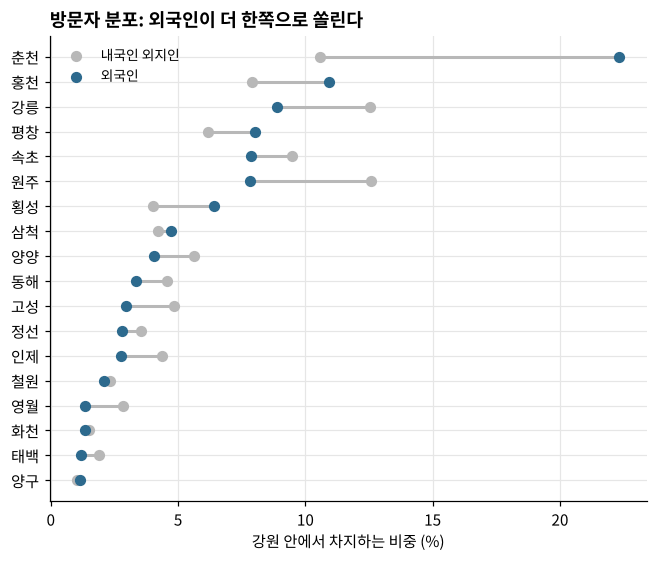

,foreign_share_pct,foreign_spend_per_visitor,foreign_medical_억원
sigun,,,
춘천시,22.34,"14,859.17",5.08
홍천군,10.94,"11,684.46",0.25
강릉시,8.90,"35,386.57",3.89
평창군,8.02,"32,192.03",0.15
속초시,7.88,"29,819.45",1.60
원주시,7.81,"18,867.79",6.05


In [12]:
s = f.sort_values("foreign_share_pct")
fig, ax = plt.subplots(figsize=(7, 5.5))
y = range(len(s))
ax.hlines(y, s["outsider_share_of_gangwon_pct"], s["foreign_share_pct"], color=MUTED, lw=2)
ax.scatter(s["outsider_share_of_gangwon_pct"], y, color=MUTED, s=40, label="내국인 외지인", zorder=3)
ax.scatter(s["foreign_share_pct"], y, color=ACCENT, s=40, label="외국인", zorder=3)
ax.set_yticks(list(y), [short(i) for i in s.index])
ax.set_xlabel("강원 안에서 차지하는 비중 (%)")
ax.set_title("방문자 분포: 외국인이 더 한쪽으로 쏠린다")
ax.legend(frameon=False, fontsize=9)
save(fig, FIG / "F_foreign_concentration.png"); plt.show()
top3 = lambda c: f[c].nlargest(3).sum()
print(f"상위 3개 시군 점유  외국인 {top3('foreign_share_pct'):.0f}%  /  내국인 외지인 {top3('outsider_share_of_gangwon_pct'):.0f}%")
f[["foreign_share_pct", "foreign_spend_per_visitor", "foreign_medical_k"]].assign(
    foreign_medical_억원=lambda x: x["foreign_medical_k"] / 1e5).drop(columns="foreign_medical_k") \
    .sort_values("foreign_share_pct", ascending=False).head(6)

**결과** 강원 외국인 방문의 22%가 춘천 한 곳에 몰리는데(내국인 기준 춘천 비중의 2배), 춘천의 외국인 1명당 지출은 약 1만 5천 원으로 강릉(3만 5천 원)·평창(3만 2천 원)의 절반이 안 된다. 외국인 의료관광 지출은 원주·춘천·강릉에 집중돼 있고, 원주가 1위다. 춘천에 온 외국인을 고지출·웰니스 지역으로 잇는 것이 지역 분산 과제다.

## 7. 종합 진단

네 가지 플래그를 조합해 시·군을 6가지 유형으로 나눴다. 규칙은 `src/gwdx/diagnose.py`의 `classify`에 있다.

In [13]:
cols = {"type": "진단 유형", "A_stay_weak": "A", "B_seasonal": "B", "C_low_spend": "C", "D_underused": "D",
        "lodging_share_pct": "숙박 비중%", "seasonality_ratio": "계절 편차", "spend_per_outsider": "1명당 지출",
        "resource_spend_ratio": "자원 대비 지출"}
view = d[list(cols)].rename(columns=cols)
for c in ["A", "B", "C", "D"]:
    view[c] = view[c].map({True: "●", False: ""})
view.index = [i + (" ★" if f.loc[i, "wellness_cluster"] else "") for i in view.index]
view

,진단 유형,A,B,C,D,숙박 비중%,계절 편차,1명당 지출,자원 대비 지출
인제군,자원 미활용·통과형,●,,●,●,2.81,2.25,"9,919.78",0.26
삼척시,자원 미활용·통과형,,,●,●,10.07,2.35,"13,887.83",0.46
영월군,자원 미활용·통과형,●,,●,●,3.91,2.35,"14,160.32",0.44
철원군,자원 미활용·통과형,●,,●,●,3.33,2.17,"11,513.31",0.30
화천군,자원 미활용·통과형,●,,●,●,3.10,1.96,"9,540.07",0.13
양구군,자원 미활용·통과형,●,,●,●,3.87,2.02,"11,534.43",0.16
평창군 ★,계절 의존 리조트형,,●,,,23.94,2.61,"18,641.04",0.90
고성군,계절 의존 리조트형,,●,●,,21.80,3.49,"13,639.12",0.72
속초시,성수기 집중형,,●,,,6.64,2.42,"25,401.90",3.30
양양군 ★,성수기 집중형,,●,,●,7.07,2.77,"16,743.57",0.57


## 8. 기준값이 바뀌어도 결론이 유지되나 (민감도 분석)

기준값 4개는 분석자가 정한 값이다. 각각을 ±20% 바꾼 81가지 조합에서 시·군의 유형이 얼마나 유지되는지 확인한다.

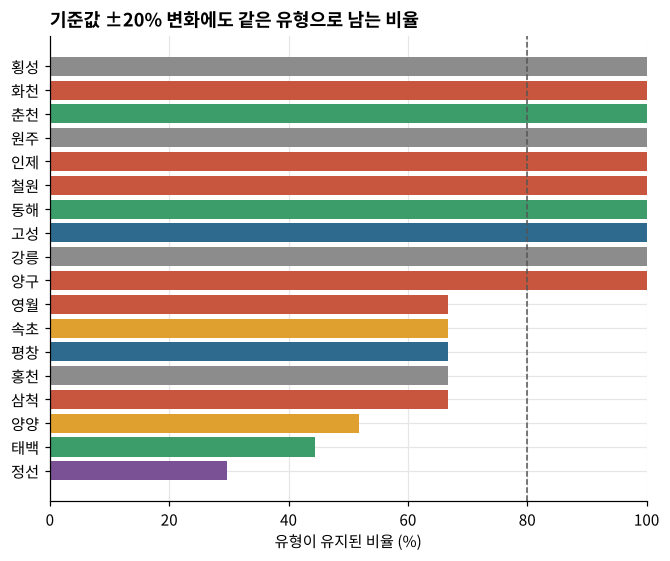

,base_type,type_kept_pct,D_on_pct
sigun,,,
정선군,자원 대비 저소비형,30.00,67.00
태백시,당일치기형,44.00,33.00
양양군,성수기 집중형,52.00,67.00
삼척시,자원 미활용·통과형,67.00,100.00
홍천군,체류·소비 거점형,67.00,0.00
평창군,계절 의존 리조트형,67.00,0.00
속초시,성수기 집중형,67.00,0.00
영월군,자원 미활용·통과형,67.00,100.00
양구군,자원 미활용·통과형,100.00,100.00


In [14]:
sens = diagnose.sensitivity(f, step=0.2)
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh([short(i) for i in sens.index], sens["type_kept_pct"],
        color=[TYPE_COLORS[t] for t in sens["base_type"]])
ax.axvline(80, color="#555", ls="--", lw=1)
ax.set_xlim(0, 100); ax.set_xlabel("유형이 유지된 비율 (%)")
ax.set_title("기준값 ±20% 변화에도 같은 유형으로 남는 비율")
save(fig, FIG / "S_sensitivity.png"); plt.show()
sens.round(0)

**결과** 자원 미활용·통과형의 핵심(인제·철원·화천·양구)과 거점형(원주·강릉·횡성), 춘천·동해의 당일치기형은 어떤 조합에서도 그대로다. 반면 정선(30%)·태백(44%)·양양(52%)은 기준값에 따라 유형이 바뀌는 **경계 지역**이다. 다만 정선·양양은 81가지 중 67%에서 D(자원 미활용)가 켜져, '자원에 비해 소비가 적다'는 진단 자체는 대체로 유지된다.

## 9. 데이터만으로 묶어도 비슷하게 나뉘나 (군집 분석 검증)

규칙 없이 네 지표(자원 대비 지출의 로그, 1명당 지출, 숙박 비중, 계절 편차)를 표준화해 k-means로 묶고, 규칙 기반 유형과 얼마나 겹치는지 본다.

In [15]:
X = pd.DataFrame({
    "log(자원 대비 지출)": np.log(f["resource_spend_ratio"]),
    "1명당 지출": f["spend_per_outsider"],
    "숙박 비중": f["lodging_share_pct"],
    "계절 편차": f["seasonality_ratio"],
})
Z = StandardScaler().fit_transform(X)
scores = []
for k in range(3, 7):
    km = KMeans(k, n_init=50, random_state=0).fit(Z)
    scores.append({"k": k, "실루엣": silhouette_score(Z, km.labels_),
                   "규칙 유형과 일치(ARI)": adjusted_rand_score(d["type"].reindex(X.index), km.labels_)})
pd.DataFrame(scores)

,k,실루엣,규칙 유형과 일치(ARI)
0,3,0.46,0.47
1,4,0.39,0.36
2,5,0.39,0.26
3,6,0.34,0.32


In [16]:
km = KMeans(3, n_init=50, random_state=0).fit(Z)
labels = pd.Series(km.labels_, index=X.index, name="군집")
centers = pd.DataFrame(StandardScaler().fit(X).inverse_transform(km.cluster_centers_), columns=X.columns)
centers["자원 대비 지출"] = np.exp(centers.pop("log(자원 대비 지출)"))
display(centers.round(2))
pd.crosstab(d["type"].reindex(X.index), labels)

,1명당 지출,숙박 비중,계절 편차,자원 대비 지출
0,"13,159.49",4.59,2.24,0.32
1,"22,601.70",7.19,1.83,1.77
2,"16,080.42",22.60,2.81,0.70


군집,0,1,2
type,,,
계절 의존 리조트형,0,0,2
당일치기형,1,2,0
성수기 집중형,1,1,0
자원 대비 저소비형,0,0,1
자원 미활용·통과형,6,0,0
체류·소비 거점형,0,4,0


**결과** 실루엣 점수가 가장 높은 k=3에서 데이터는 (1) 자원 대비 지출과 1명당 지출이 모두 낮은 군 지역, (2) 1명당 지출이 높은 거점·당일치기 도시, (3) 숙박 비중과 계절 편차가 큰 리조트 지역으로 나뉜다. 규칙 기반 유형과의 일치도(ARI)는 약 0.47로 중간 수준이다. 큰 줄기(미활용 / 거점 / 리조트)는 데이터에서도 그대로 나오고, 규칙 기반 유형은 그 안을 처방이 다른 단위로 더 잘게 나눈 것이다.

## 10. 가설 E · 의료 연계: 의료웰니스를 받을 준비가 된 곳은?

정부는 의료와 웰니스를 묶은 관광을 고부가 시장으로 키우려 한다. 웰니스 자원 근처에 종합병원이 있어야 의료웰니스 상품이 가능하다. 건강보험심사평가원 병원기본목록(강원 의료기관 1,992곳)으로 시·군의 의료 인프라와, 웰니스 자원에서 가장 가까운 종합병원(상급종합·종합병원)까지의 직선거리를 계산했다.

In [17]:
med, sites = features.medical_features(api)
fm = f.join(med)
cols = {"general_hospitals": "종합병원", "doctors": "의사 수", "korean_medicine": "한방 기관",
        "resource_to_general_km": "자원→종합병원(km, 중앙값)", "foreign_medical_k": "외국인 의료관광(천원)"}
view = fm[list(cols)].rename(columns=cols).sort_values("자원→종합병원(km, 중앙값)")
view.index = [i + (" ★" if fm.loc[i, "wellness_cluster"] else "") for i in view.index]
view

,종합병원,의사 수,한방 기관,"자원→종합병원(km, 중앙값)",외국인 의료관광(천원)
속초시,2,192,23,3.18,"159,637.00"
강릉시,4,784,59,6.20,"389,452.00"
태백시,1,76,7,7.69,"9,325.00"
동해시,2,168,20,7.71,"41,671.00"
춘천시,2,974,67,9.13,"508,048.00"
원주시 ★,2,1204,116,9.53,"604,992.00"
영월군,1,59,4,11.36,"10,038.00"
삼척시,1,106,11,11.96,"42,748.00"
양양군 ★,0,25,4,16.34,"4,693.00"
정선군 ★,0,44,5,21.37,"4,735.00"


의사 수 vs 외국인 의료관광 지출  Spearman ρ = 0.85, p = 0.0000
종합병원 수 vs 외국인 의료관광 지출  Spearman ρ = 0.85, p = 0.0000
자원→종합병원 거리 vs 외국인 의료관광 지출  Spearman ρ = -0.66, p = 0.0028
종합병원이 없는 시군: 고성군, 양구군, 양양군, 인제군, 정선군, 철원군, 평창군, 화천군, 횡성군


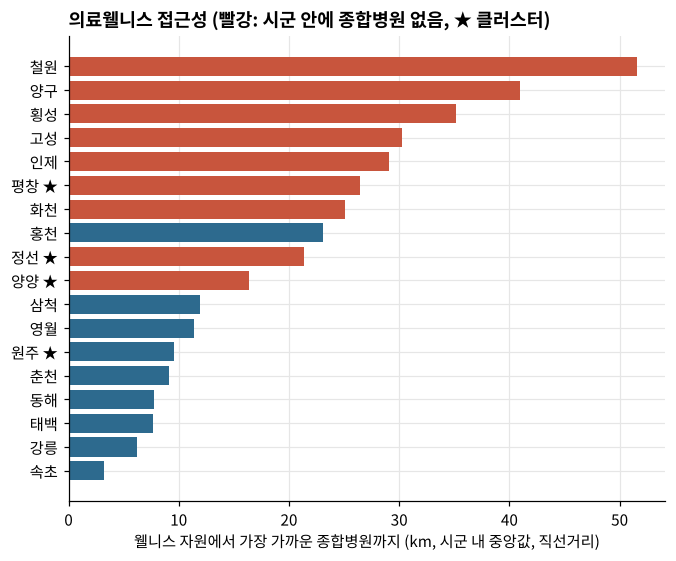

In [18]:
s = fm.sort_values("resource_to_general_km")
fig, ax = plt.subplots(figsize=(7, 5.5))
colors = [WARN if g == 0 else ACCENT for g in s["general_hospitals"]]
ax.barh([short(i) + (" ★" if s.loc[i, "wellness_cluster"] else "") for i in s.index], s["resource_to_general_km"], color=colors)
ax.set_xlabel("웰니스 자원에서 가장 가까운 종합병원까지 (km, 시군 내 중앙값, 직선거리)")
ax.set_title("의료웰니스 접근성 (빨강: 시군 안에 종합병원 없음, ★ 클러스터)")
save(fig, FIG / "E_medical_access.png"); plt.show()
for a, label in [("doctors", "의사 수"), ("general_hospitals", "종합병원 수"), ("resource_to_general_km", "자원→종합병원 거리")]:
    r = stats.spearmanr(fm[a], fm["foreign_medical_k"])
    print(f"{label} vs 외국인 의료관광 지출  Spearman ρ = {r.statistic:.2f}, p = {r.pvalue:.4f}")
print("종합병원이 없는 시군:", ", ".join(fm.index[fm["general_hospitals"] == 0]))

**결과** 강원의 종합병원 16곳은 9개 시·군에 몰려 있고, 나머지 9개 시·군에는 한 곳도 없다. 웰니스 클러스터 4곳 중 **원주만 종합병원(상급종합 포함 2곳)이 있고, 양양·정선·평창은 0곳**이다. 이 세 곳의 웰니스 자원에서 가장 가까운 종합병원까지는 중앙값 16~26km다. 외국인 의료관광 지출은 의사 수와 매우 강하게 함께 움직인다(ρ≈0.85). 의료웰니스는 지금 구조로는 **원주를 거점으로 하고, 양양·정선·평창은 원주·강릉 병원과 연계하는 형태**가 현실적이다.

직선거리라 실제 이동 시간과 다르고, 외국인 의료관광 지출은 강원 전체 약 18억 원으로 규모가 작다는 점을 감안해야 한다.

## 11. 결론과 한계

**결론**
1. 강원의 웰니스 자원은 방문을 부르지만 소비로는 약하게 이어진다. 소비와 가장 강하게 함께 움직이는 것은 숙박 인프라다. **'받을 준비(체류 기반)'가 병목**이라는 가설을 지지한다.
2. 처방은 유형별로 달라야 한다.
   - 군 지역(인제·화천·양구·철원·영월·삼척): 웰니스 자원과 숙박을 묶은 체류 상품
   - 리조트·해안 지역(평창·고성·양양·속초): 비수기 웰니스 프로그램
   - 도시(춘천·동해): 1박 유도
   - 거점(원주·강릉): 주변 지역 연계
3. 클러스터 4곳 중 양양·정선은 자원 대비 소비가 낮다. 의료웰니스는 종합병원과 외국인 의료관광 지출이 모두 있는 **원주가 유일한 거점 후보**이고, 양양·정선·평창은 원주·강릉 병원과 연계해야 한다.

**한계**
- 방문자 수는 같은 사람을 여러 번 셀 수 있고, 외지인에는 출장·통근이 섞여 있다. 시·군끼리 비교하는 용도로만 썼다.
- 카드 가맹점 위치 기준이라 숙박 앱·여행사 선결제가 빠져 숙박 비중과 외국인 지출이 낮게 잡힐 수 있다.
- 웰니스 자원은 관광공사 등록 기준이다. 실제 업소 수(인허가 데이터)와 다르다.
- 18개 시·군의 횡단면 비교라 상관은 인과가 아니다.

**다음 단계** 도로 기준 이동 시간으로 의료 접근성 보완, 숙박 인허가 데이터로 숙박 인프라 지표 보완.